In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/sam123364/MLOPS/main/reports/user_assignment/engineered_district_year_features.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (375, 17)


,district_name,year,annual_total_mm,rainy_days_count,heavy_rain_days_count,very_heavy_rain_days_count,max_1day_rainfall_mm,observed_days,ne_monsoon_total_mm,pre_monsoon_total_mm,sw_monsoon_total_mm,winter_total_mm,sw_max_3day_rainfall_mm,pci,expected_days,complete_calendar_year,data_quality_note
0,Chikkaballapur,1901,669.80620,63,3,0,37.472637,335,212.84123,118.85554,298.30374,39.805740,52.504290,14.413944,365,False,Incomplete calendar year; exclude from full-ye...
1,Chikkaballapur,1902,731.62650,62,5,1,66.769420,365,254.26576,132.01985,334.04350,11.297449,61.237272,15.854124,365,True,Complete calendar year
2,Chikkaballapur,1903,1147.13390,91,13,3,75.399930,365,506.72780,74.75917,562.73004,2.916829,60.723126,18.199440,365,True,Complete calendar year
3,Chikkaballapur,1904,459.48970,40,3,0,39.711895,366,113.26890,124.56455,219.63830,2.017939,51.166959,18.153635,366,True,Complete calendar year
4,Chikkaballapur,1905,596.41534,58,4,0,38.628128,365,188.10635,133.90283,267.81256,6.593601,70.819246,17.645483,365,True,Complete calendar year


In [2]:
# 1. Check dataset size
print("Dataset shape:", df.shape)

# 2. Check column names and data types
print("\nDataset information:")
df.info()

# 3. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Check districts and years
print("\nDistricts:")
print(df["district_name"].unique())

print("\nYear range:", df["year"].min(), "-", df["year"].max())

# 6. Display basic rainfall statistics
print("\nRainfall statistics:")
print(df[["annual_total_mm", "max_1day_rainfall_mm"]].describe())

Dataset shape: (375, 17)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   district_name               375 non-null    object 
 1   year                        375 non-null    int64  
 2   annual_total_mm             375 non-null    float64
 3   rainy_days_count            375 non-null    int64  
 4   heavy_rain_days_count       375 non-null    int64  
 5   very_heavy_rain_days_count  375 non-null    int64  
 6   max_1day_rainfall_mm        375 non-null    float64
 7   observed_days               375 non-null    int64  
 8   ne_monsoon_total_mm         375 non-null    float64
 9   pre_monsoon_total_mm        375 non-null    float64
 10  sw_monsoon_total_mm         375 non-null    float64
 11  winter_total_mm             375 non-null    float64
 12  sw_max_3day_rainfall_mm     375 non-null    f

Average annual rainfall by district:
district_name
Kolar             771.52
Tumakuru          685.20
Chikkaballapur    665.90
Name: annual_total_mm, dtype: float64


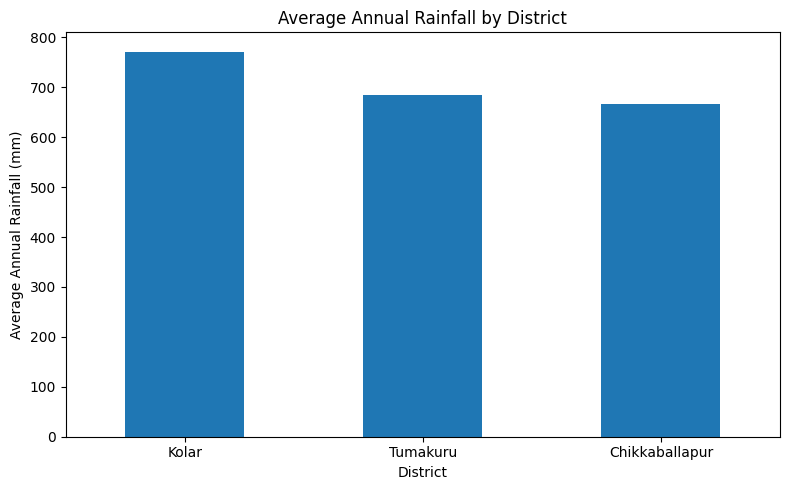

In [3]:
import matplotlib.pyplot as plt

# Keep only complete calendar years
df_complete = df[df["complete_calendar_year"] == True].copy()

# Calculate average annual rainfall for each district
avg_rainfall = (
    df_complete.groupby("district_name")["annual_total_mm"]
    .mean()
    .sort_values(ascending=False)
)

print("Average annual rainfall by district:")
print(avg_rainfall.round(2))

# Create bar chart
avg_rainfall.plot(kind="bar", figsize=(8, 5))

plt.title("Average Annual Rainfall by District")
plt.xlabel("District")
plt.ylabel("Average Annual Rainfall (mm)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

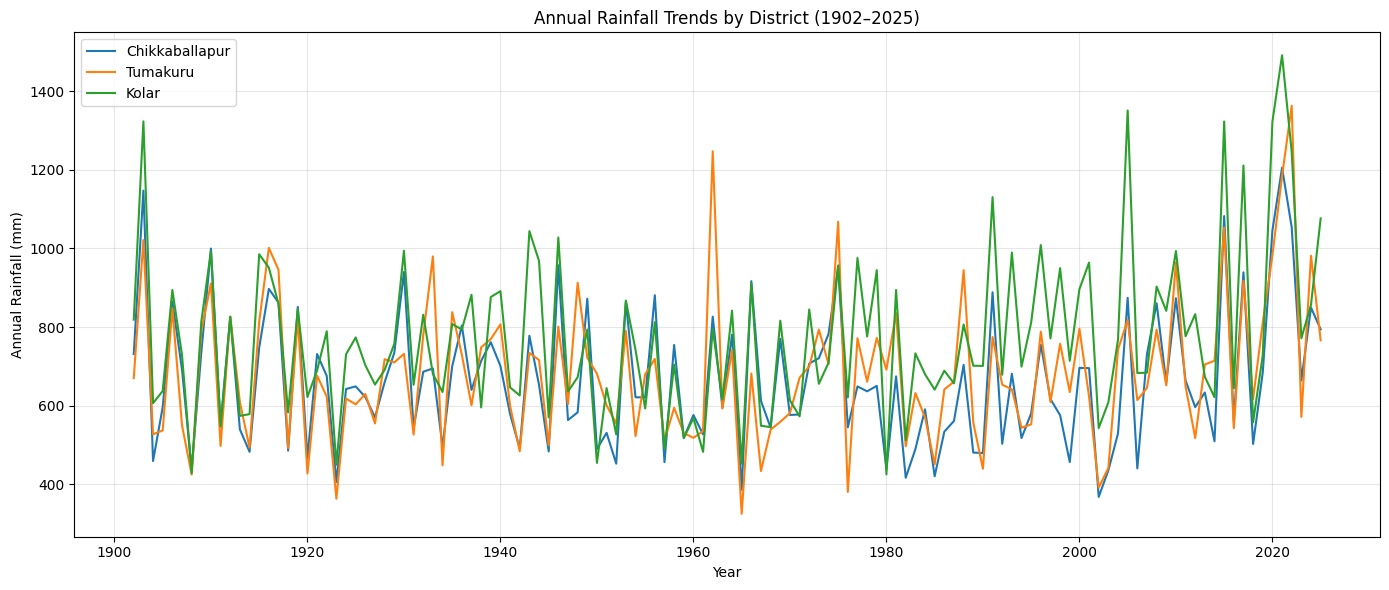

In [4]:
import matplotlib.pyplot as plt

# Exclude incomplete calendar years
df_complete = df[df["complete_calendar_year"] == True].copy()

# Sort data by year
df_complete = df_complete.sort_values("year")

# Plot annual rainfall trends
plt.figure(figsize=(14, 6))

for district in df_complete["district_name"].unique():
    district_data = df_complete[
        df_complete["district_name"] == district
    ]

    plt.plot(
        district_data["year"],
        district_data["annual_total_mm"],
        label=district,
        linewidth=1.5
    )

plt.title("Annual Rainfall Trends by District (1902–2025)")
plt.xlabel("Year")
plt.ylabel("Annual Rainfall (mm)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Exclude incomplete calendar years
df_complete = df[df["complete_calendar_year"] == True].copy()

# Find the wettest and driest year for each district
for district in df_complete["district_name"].unique():

    district_data = df_complete[
        df_complete["district_name"] == district
    ]

    wettest = district_data.loc[
        district_data["annual_total_mm"].idxmax()
    ]

    driest = district_data.loc[
        district_data["annual_total_mm"].idxmin()
    ]

    print(f"\nDistrict: {district}")

    print(
        f"Wettest year: {int(wettest['year'])} "
        f"| Rainfall: {wettest['annual_total_mm']:.2f} mm"
    )

    print(
        f"Driest year: {int(driest['year'])} "
        f"| Rainfall: {driest['annual_total_mm']:.2f} mm"
    )



District: Chikkaballapur
Wettest year: 2021 | Rainfall: 1205.37 mm
Driest year: 2002 | Rainfall: 368.38 mm

District: Kolar
Wettest year: 2021 | Rainfall: 1491.34 mm
Driest year: 1980 | Rainfall: 425.56 mm

District: Tumakuru
Wettest year: 2022 | Rainfall: 1363.10 mm
Driest year: 1965 | Rainfall: 325.37 mm


Average Southwest Monsoon Rainfall:
district_name
Kolar             379.25
Tumakuru          366.04
Chikkaballapur    354.46
Name: sw_monsoon_total_mm, dtype: float64


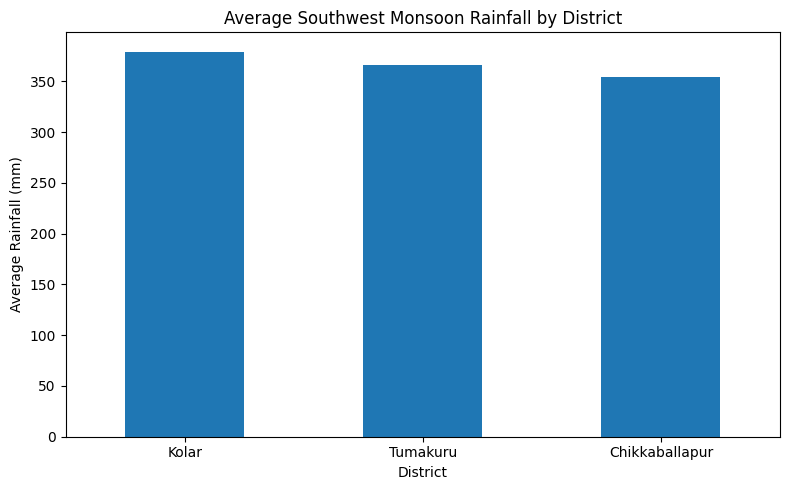

In [6]:
import matplotlib.pyplot as plt

# Exclude incomplete calendar years
df_complete = df[df["complete_calendar_year"] == True].copy()

# Calculate average southwest monsoon rainfall by district
sw_avg = (
    df_complete.groupby("district_name")["sw_monsoon_total_mm"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Southwest Monsoon Rainfall:")
print(sw_avg.round(2))

# Create graph
plt.figure(figsize=(8, 5))

sw_avg.plot(kind="bar")

plt.title("Average Southwest Monsoon Rainfall by District")
plt.xlabel("District")
plt.ylabel("Average Rainfall (mm)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Average extreme rainfall days per year:
                heavy_rain_days_count  very_heavy_rain_days_count
district_name                                                    
Chikkaballapur                    4.4                        0.48
Kolar                             5.4                        0.64
Tumakuru                          4.0                        0.29


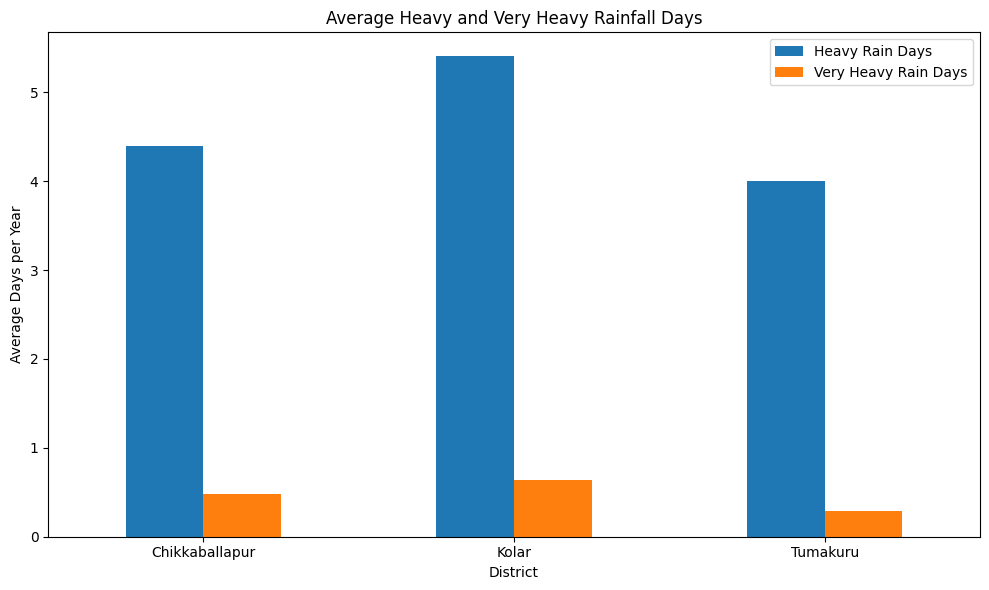

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Exclude incomplete calendar years
df_complete = df[df["complete_calendar_year"] == True].copy()

# Calculate average heavy-rainfall days by district
rain_days = df_complete.groupby("district_name")[
    ["heavy_rain_days_count", "very_heavy_rain_days_count"]
].mean()

print("Average extreme rainfall days per year:")
print(rain_days.round(2))

# Create a grouped bar chart
rain_days.plot(kind="bar", figsize=(10, 6))

plt.title("Average Heavy and Very Heavy Rainfall Days")
plt.xlabel("District")
plt.ylabel("Average Days per Year")
plt.xticks(rotation=0)
plt.legend(["Heavy Rain Days", "Very Heavy Rain Days"])
plt.tight_layout()
plt.show()


Correlation matrix:
                            annual_total_mm  rainy_days_count  \
annual_total_mm                        1.00              0.85   
rainy_days_count                       0.85              1.00   
heavy_rain_days_count                  0.81              0.48   
very_heavy_rain_days_count             0.50              0.20   
max_1day_rainfall_mm                   0.55              0.22   
sw_monsoon_total_mm                    0.76              0.65   
ne_monsoon_total_mm                    0.75              0.62   
pre_monsoon_total_mm                   0.42              0.37   
winter_total_mm                        0.13              0.12   
pci                                   -0.11             -0.25   

                            heavy_rain_days_count  very_heavy_rain_days_count  \
annual_total_mm                              0.81                        0.50   
rainy_days_count                             0.48                        0.20   
heavy_rain_days_count

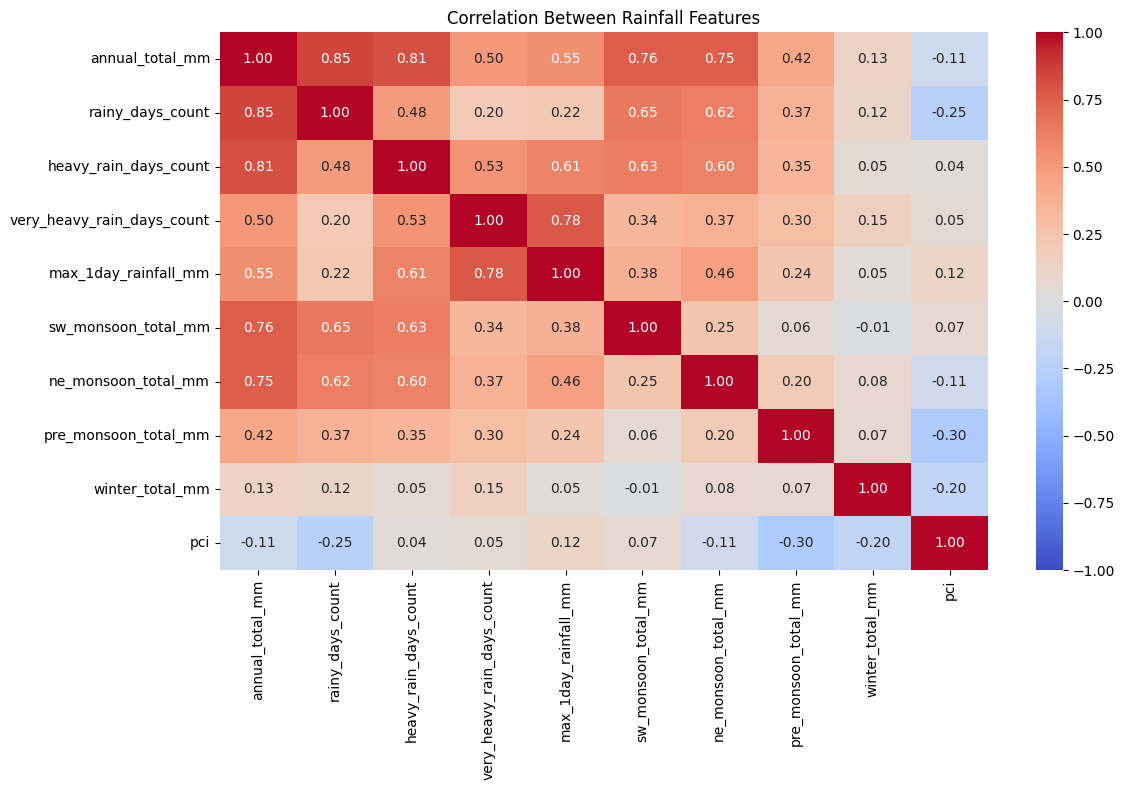

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select complete calendar years
df_complete = df[df["complete_calendar_year"] == True].copy()

# Select important numerical features
features = [
    "annual_total_mm",
    "rainy_days_count",
    "heavy_rain_days_count",
    "very_heavy_rain_days_count",
    "max_1day_rainfall_mm",
    "sw_monsoon_total_mm",
    "ne_monsoon_total_mm",
    "pre_monsoon_total_mm",
    "winter_total_mm",
    "pci"
]

# Calculate correlations
correlation = df_complete[features].corr()

print("Correlation matrix:")
print(correlation.round(2))

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Rainfall Features")
plt.tight_layout()
plt.show()

In [9]:
# Sort data by district and year
df_ml = df.sort_values(
    ["district_name", "year"]
).copy()

# Keep only complete calendar years
df_ml = df_ml[
    df_ml["complete_calendar_year"] == True
].copy()

# Display the data we'll use
print("Dataset shape:", df_ml.shape)

print("\nYears available:")
print(df_ml.groupby("district_name")["year"].agg(["min", "max", "count"]))

print("\nPreview:")
display(df_ml[
    ["district_name", "year", "annual_total_mm"]
].head(10))

Dataset shape: (372, 17)

Years available:
                 min   max  count
district_name                    
Chikkaballapur  1902  2025    124
Kolar           1902  2025    124
Tumakuru        1902  2025    124

Preview:


,district_name,year,annual_total_mm
1,Chikkaballapur,1902,731.62650
2,Chikkaballapur,1903,1147.13390
3,Chikkaballapur,1904,459.48970
4,Chikkaballapur,1905,596.41534
5,Chikkaballapur,1906,865.08990
6,Chikkaballapur,1907,692.36346
7,Chikkaballapur,1908,438.13474
8,Chikkaballapur,1909,735.32370
9,Chikkaballapur,1910,999.81580
10,Chikkaballapur,1911,552.10350


In [10]:
# Sort data chronologically within each district
df_ml = df_ml.sort_values(
    ["district_name", "year"]
).copy()

# Create the target: next year's annual rainfall
df_ml["target_next_year_rainfall_mm"] = (
    df_ml.groupby("district_name")["annual_total_mm"].shift(-1)
)

# Identify the year we're predicting
df_ml["target_year"] = (
    df_ml.groupby("district_name")["year"].shift(-1)
)

# Keep rows where the following year's data exists
df_ml = df_ml.dropna(
    subset=["target_next_year_rainfall_mm"]
).copy()

print("Dataset shape:", df_ml.shape)

display(
    df_ml[
        [
            "district_name",
            "year",
            "annual_total_mm",
            "target_year",
            "target_next_year_rainfall_mm"
        ]
    ].head(10)
)

Dataset shape: (369, 19)


,district_name,year,annual_total_mm,target_year,target_next_year_rainfall_mm
1,Chikkaballapur,1902,731.62650,1903.0,1147.13390
2,Chikkaballapur,1903,1147.13390,1904.0,459.48970
3,Chikkaballapur,1904,459.48970,1905.0,596.41534
4,Chikkaballapur,1905,596.41534,1906.0,865.08990
5,Chikkaballapur,1906,865.08990,1907.0,692.36346
6,Chikkaballapur,1907,692.36346,1908.0,438.13474
7,Chikkaballapur,1908,438.13474,1909.0,735.32370
8,Chikkaballapur,1909,735.32370,1910.0,999.81580
9,Chikkaballapur,1910,999.81580,1911.0,552.10350
10,Chikkaballapur,1911,552.10350,1912.0,825.51184


In [11]:
# Check whether target_year is exactly one year after year
df_ml["target_year"] = df_ml["target_year"].astype(int)

df_ml["year_gap"] = df_ml["target_year"] - df_ml["year"]

print("Year gaps:")
print(df_ml["year_gap"].value_counts().sort_index())

# Show any rows where years are not consecutive
gaps = df_ml[df_ml["year_gap"] != 1]

print("\nNon-consecutive year pairs:", len(gaps))

if len(gaps) > 0:
    display(
        gaps[
            ["district_name", "year", "target_year", "year_gap"]
        ].head(20)
    )
else:
    print("All target years are consecutive.")

Year gaps:
year_gap
1    369
Name: count, dtype: int64

Non-consecutive year pairs: 0
All target years are consecutive.


In [12]:
# Select features available from the current year
features = [
    "annual_total_mm",
    "rainy_days_count",
    "heavy_rain_days_count",
    "very_heavy_rain_days_count",
    "max_1day_rainfall_mm",
    "sw_monsoon_total_mm",
    "ne_monsoon_total_mm",
    "pre_monsoon_total_mm",
    "winter_total_mm",
    "pci",
    "district_name"
]

target = "target_next_year_rainfall_mm"

# Check for missing values in selected features
print("Missing values in features:")
print(df_ml[features].isnull().sum())

print("\nTarget missing values:")
print(df_ml[target].isnull().sum())

print("\nFeatures selected:", len(features))
print("Rows available for modelling:", len(df_ml))


Missing values in features:
annual_total_mm               0
rainy_days_count              0
heavy_rain_days_count         0
very_heavy_rain_days_count    0
max_1day_rainfall_mm          0
sw_monsoon_total_mm           0
ne_monsoon_total_mm           0
pre_monsoon_total_mm          0
winter_total_mm               0
pci                           0
district_name                 0
dtype: int64

Target missing values:
0

Features selected: 11
Rows available for modelling: 369


In [13]:
# Sort data by the year being predicted
df_ml = df_ml.sort_values(["target_year", "district_name"]).copy()

# Use target years up to 2019 for training
train = df_ml[df_ml["target_year"] <= 2019].copy()

# Use target years from 2020 onwards for testing
test = df_ml[df_ml["target_year"] >= 2020].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining target-year range:")
print(train["target_year"].min(), "to", train["target_year"].max())

print("\nTesting target-year range:")
print(test["target_year"].min(), "to", test["target_year"].max())

Training rows: 351
Testing rows: 18

Training target-year range:
1903 to 2019

Testing target-year range:
2020 to 2025


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Separate input features (X) and target (y)
X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

# Identify numerical and categorical columns
numeric_features = [col for col in features if col != "district_name"]
categorical_features = ["district_name"]

# Convert district names into numerical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("district", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numbers", "passthrough", numeric_features)
    ]
)

# Create the ML pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

# Predict rainfall for the test data
y_pred = model.predict(X_test)

print("\nFirst 10 actual rainfall values:")
print(y_test.head(10).round(2).to_list())

print("\nFirst 10 predicted rainfall values:")
print(y_pred[:10].round(2).tolist())


Linear Regression model trained successfully!

First 10 actual rainfall values:
[1045.88, 1322.35, 982.19, 1205.37, 1491.34, 1184.47, 1054.19, 1245.33, 1363.1, 664.18]

First 10 predicted rainfall values:
[631.86, 745.61, 624.21, 539.7, 604.73, 655.26, 540.4, 532.78, 579.91, 612.47]


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("-" * 35)
print(f"Mean Absolute Error (MAE): {mae:.2f} mm")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} mm")
print(f"R-squared (R²): {r2:.3f}")

MODEL EVALUATION RESULTS
-----------------------------------
Mean Absolute Error (MAE): 379.76 mm
Root Mean Squared Error (RMSE): 462.20 mm
R-squared (R²): -2.464


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline: predict next year's rainfall using this year's rainfall
baseline_pred = test["annual_total_mm"].values

# Evaluate the baseline
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("BASELINE MODEL RESULTS")
print("-" * 35)
print(f"MAE:  {baseline_mae:.2f} mm")
print(f"RMSE: {baseline_rmse:.2f} mm")
print(f"R²:   {baseline_r2:.3f}")

print("\nCOMPARISON")
print("-" * 35)
print(f"Linear Regression MAE: {mae:.2f} mm")
print(f"Baseline MAE:          {baseline_mae:.2f} mm")

if baseline_mae < mae:
    print("\nBaseline performs better based on MAE.")
else:
    print("\nLinear Regression performs better based on MAE.")

BASELINE MODEL RESULTS
-----------------------------------
MAE:  280.93 mm
RMSE: 335.93 mm
R²:   -0.830

COMPARISON
-----------------------------------
Linear Regression MAE: 379.76 mm
Baseline MAE:          280.93 mm

Baseline performs better based on MAE.


In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import numpy as np

# Preprocess district names and numerical features
preprocessor_rf = ColumnTransformer(
    transformers=[
        ("district", OneHotEncoder(handle_unknown="ignore"), ["district_name"]),
        ("numbers", "passthrough",
         [col for col in features if col != "district_name"])
    ]
)

# Create Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        random_state=42
    ))
])

# Train using historical data only
rf_model.fit(X_train, y_train)

# Predict rainfall for test years
rf_pred = rf_model.predict(X_test)

# Evaluate
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("RANDOM FOREST RESULTS")
print("-" * 35)
print(f"MAE:  {rf_mae:.2f} mm")
print(f"RMSE: {rf_rmse:.2f} mm")
print(f"R²:   {rf_r2:.3f}")

print("\nMODEL COMPARISON")
print("-" * 35)
print(f"Persistence baseline MAE: {baseline_mae:.2f} mm")
print(f"Linear Regression MAE:    {mae:.2f} mm")
print(f"Random Forest MAE:        {rf_mae:.2f} mm")

RANDOM FOREST RESULTS
-----------------------------------
MAE:  357.15 mm
RMSE: 428.58 mm
R²:   -1.978

MODEL COMPARISON
-----------------------------------
Persistence baseline MAE: 280.93 mm
Linear Regression MAE:    379.76 mm
Random Forest MAE:        357.15 mm


,District,Target Year,Actual Rainfall,Baseline Prediction,Linear Regression,Random Forest
0,Chikkaballapur,2020,1045.88,684.50,631.86,647.24
1,Kolar,2020,1322.35,728.74,745.61,688.83
2,Tumakuru,2020,982.19,812.24,624.21,670.13
3,Chikkaballapur,2021,1205.37,1045.88,539.70,658.05
4,Kolar,2021,1491.34,1322.35,604.73,659.93
5,Tumakuru,2021,1184.47,982.19,655.26,695.65
6,Chikkaballapur,2022,1054.19,1205.37,540.40,627.18
7,Kolar,2022,1245.33,1491.34,532.78,656.10
8,Tumakuru,2022,1363.10,1184.47,579.91,638.29
9,Chikkaballapur,2023,664.18,1054.19,612.47,629.34


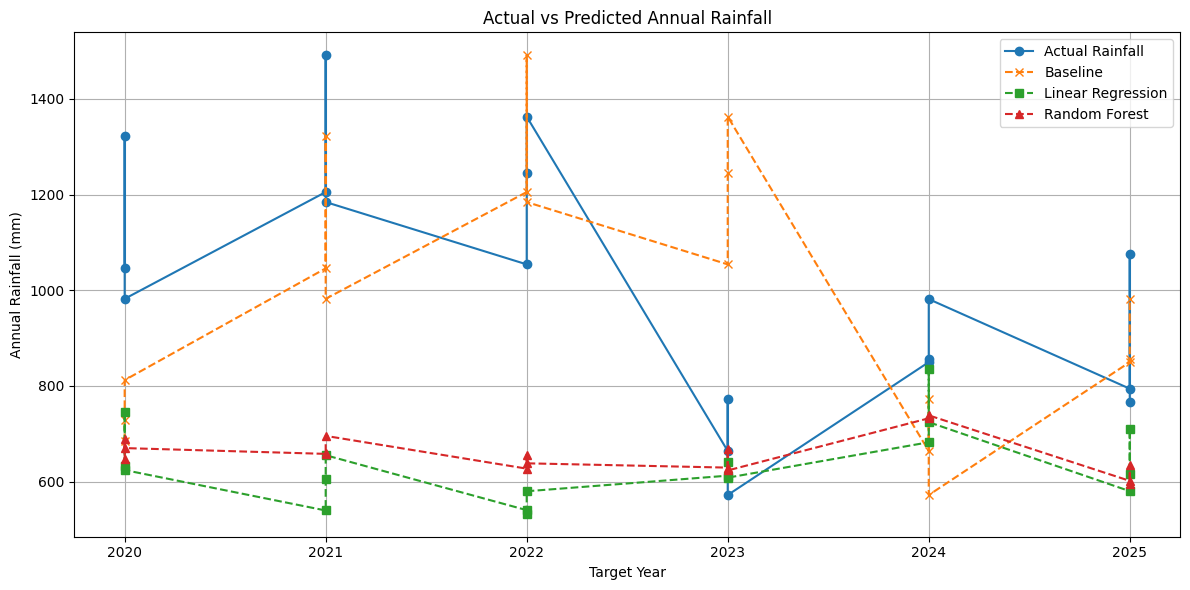

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# Create comparison table
comparison = pd.DataFrame({
    "District": test["district_name"].values,
    "Target Year": test["target_year"].values,
    "Actual Rainfall": y_test.values,
    "Baseline Prediction": baseline_pred,
    "Linear Regression": y_pred,
    "Random Forest": rf_pred
})

# Sort by year for a clear graph
comparison = comparison.sort_values(["Target Year", "District"])

# Display actual and predicted values
display(comparison.round(2))

# Plot actual vs predicted rainfall
plt.figure(figsize=(12, 6))

plt.plot(
    comparison["Target Year"],
    comparison["Actual Rainfall"],
    marker="o",
    label="Actual Rainfall"
)

plt.plot(
    comparison["Target Year"],
    comparison["Baseline Prediction"],
    marker="x",
    linestyle="--",
    label="Baseline"
)

plt.plot(
    comparison["Target Year"],
    comparison["Linear Regression"],
    marker="s",
    linestyle="--",
    label="Linear Regression"
)

plt.plot(
    comparison["Target Year"],
    comparison["Random Forest"],
    marker="^",
    linestyle="--",
    label="Random Forest"
)

plt.xlabel("Target Year")
plt.ylabel("Annual Rainfall (mm)")
plt.title("Actual vs Predicted Annual Rainfall")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
# Calculate prediction errors for each model
comparison["Baseline Error"] = (
    comparison["Actual Rainfall"] - comparison["Baseline Prediction"]
).abs()

comparison["Linear Regression Error"] = (
    comparison["Actual Rainfall"] - comparison["Linear Regression"]
).abs()

comparison["Random Forest Error"] = (
    comparison["Actual Rainfall"] - comparison["Random Forest"]
).abs()

# Display errors for each district and year
display(
    comparison[
        [
            "District",
            "Target Year",
            "Actual Rainfall",
            "Baseline Error",
            "Linear Regression Error",
            "Random Forest Error"
        ]
    ].round(2)
)

# Find the largest error for each model
print("LARGEST PREDICTION ERRORS")
print("-" * 35)

for model_name, error_col in [
    ("Baseline", "Baseline Error"),
    ("Linear Regression", "Linear Regression Error"),
    ("Random Forest", "Random Forest Error")
]:
    worst = comparison.loc[comparison[error_col].idxmax()]

    print(f"\n{model_name}:")
    print("District:", worst["District"])
    print("Target year:", int(worst["Target Year"]))
    print("Absolute error:", round(worst[error_col], 2), "mm")

,District,Target Year,Actual Rainfall,Baseline Error,Linear Regression Error,Random Forest Error
0,Chikkaballapur,2020,1045.88,361.37,414.02,398.64
1,Kolar,2020,1322.35,593.61,576.74,633.52
2,Tumakuru,2020,982.19,169.95,357.98,312.06
3,Chikkaballapur,2021,1205.37,159.49,665.66,547.32
4,Kolar,2021,1491.34,168.99,886.61,831.41
5,Tumakuru,2021,1184.47,202.28,529.21,488.82
6,Chikkaballapur,2022,1054.19,151.18,513.79,427.01
7,Kolar,2022,1245.33,246.01,712.55,589.23
8,Tumakuru,2022,1363.10,178.63,783.19,724.81
9,Chikkaballapur,2023,664.18,390.01,51.71,34.84


LARGEST PREDICTION ERRORS
-----------------------------------

Baseline:
District: Tumakuru
Target year: 2023
Absolute error: 791.1 mm

Linear Regression:
District: Kolar
Target year: 2021
Absolute error: 886.61 mm

Random Forest:
District: Kolar
Target year: 2021
Absolute error: 831.41 mm


In [20]:
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
from pathlib import Path

# Compare all three models
results = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE_mm": [
        baseline_mae,
        mae,
        rf_mae
    ],
    "RMSE_mm": [
        baseline_rmse,
        rmse,
        rf_rmse
    ],
    "R2": [
        baseline_r2,
        r2,
        rf_r2
    ]
})

results = results.sort_values("MAE_mm")

print("MODEL EVALUATION SUMMARY")
display(results.round(3))

# Save the results
results.to_csv("rainfall_model_evaluation.csv", index=False)

print("\nSaved: rainfall_model_evaluation.csv")

# Download the CSV from Colab
from google.colab import files
files.download("rainfall_model_evaluation.csv")

MODEL EVALUATION SUMMARY


,Model,MAE_mm,RMSE_mm,R2
0,Persistence Baseline,280.932,335.933,-0.830
2,Random Forest,357.155,428.581,-1.978
1,Linear Regression,379.756,462.203,-2.464



Saved: rainfall_model_evaluation.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# Select useful columns for the prediction report
prediction_report = comparison[
    [
        "District",
        "Target Year",
        "Actual Rainfall",
        "Baseline Prediction",
        "Linear Regression",
        "Random Forest"
    ]
].copy()

# Calculate absolute prediction errors
prediction_report["Baseline Error"] = (
    prediction_report["Actual Rainfall"]
    - prediction_report["Baseline Prediction"]
).abs()

prediction_report["Linear Regression Error"] = (
    prediction_report["Actual Rainfall"]
    - prediction_report["Linear Regression"]
).abs()

prediction_report["Random Forest Error"] = (
    prediction_report["Actual Rainfall"]
    - prediction_report["Random Forest"]
).abs()

# Round values for readability
prediction_report = prediction_report.round(2)

# Save to CSV
prediction_report.to_csv(
    "rainfall_predictions_report.csv",
    index=False
)

print("Prediction report created successfully!")
print("Total predictions:", len(prediction_report))

display(prediction_report.head(10))

# Download the report
from google.colab import files
files.download("rainfall_predictions_report.csv")

Prediction report created successfully!
Total predictions: 18


,District,Target Year,Actual Rainfall,Baseline Prediction,Linear Regression,Random Forest,Baseline Error,Linear Regression Error,Random Forest Error
0,Chikkaballapur,2020,1045.88,684.50,631.86,647.24,361.37,414.02,398.64
1,Kolar,2020,1322.35,728.74,745.61,688.83,593.61,576.74,633.52
2,Tumakuru,2020,982.19,812.24,624.21,670.13,169.95,357.98,312.06
3,Chikkaballapur,2021,1205.37,1045.88,539.70,658.05,159.49,665.66,547.32
4,Kolar,2021,1491.34,1322.35,604.73,659.93,168.99,886.61,831.41
5,Tumakuru,2021,1184.47,982.19,655.26,695.65,202.28,529.21,488.82
6,Chikkaballapur,2022,1054.19,1205.37,540.40,627.18,151.18,513.79,427.01
7,Kolar,2022,1245.33,1491.34,532.78,656.10,246.01,712.55,589.23
8,Tumakuru,2022,1363.10,1184.47,579.91,638.29,178.63,783.19,724.81
9,Chikkaballapur,2023,664.18,1054.19,612.47,629.34,390.01,51.71,34.84


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
prediction_report.to_csv("rainfall_predictions_report.csv", index=False)

from google.colab import files
files.download("rainfall_predictions_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>